**Project Title:-Customer Churn Prediction and Analysis in the Telecom Industry**

**1.Aim**-To analyze customer behavior and develop a Machine Learning model that predicts whether a telecom customer is likely to leave the company or continue using its services.

**2.Problem Statement**-Telecommunication companies face challenges in retaining customers, which can lead to revenue loss and increased customer acquisition costs. This project aims to analyze customer demographics, service usage, contract types, and billing information to identify patterns associated with customer churn. A Machine Learning model will be developed to predict customer churn and help companies make data-driven decisions to improve customer retention.

**3.Dataset**-Dataset name: customer_churn_data.csv
Dataset size: 1,000 customer records and 10 columns, according to the provided dataset description.
Data source: Kaggle

**4.Input Features**-The following columns will be used as input features for prediction:

Age: Age of the customer.

Gender: Gender of the customer.

Tenure: Number of months the customer has stayed with the company.

MonthlyCharges: Monthly service charges.

ContractType: Type of contract selected by the customer.

InternetService: Type of internet service used.

TechSupport: Whether the customer has technical support.

**5.Target Variable**-Target column: Churn
Yes (1): The customer has left the company.
No (0): The customer has remained with the company.

**6-Expected Outcome**-The expected outcome is a trained Machine Learning classification model that predicts whether a customer is likely to churn or stay with the company. The project will also identify customer characteristics associated with churn and provide insights that may help businesses develop targeted customer retention strategies.
The trained model can be integrated into a Streamlit application, allowing users to enter customer details and receive a churn prediction.
Actual model performance and business insights will be reported after completing the analysis and evaluating the model on test data.

In [2]:
import pandas as pd

In [3]:
data=pd.read_csv("customer_churn_data.csv")

In [4]:
data.head()

,CustomerID,Age,Gender,Tenure,MonthlyCharges,ContractType,InternetService,TotalCharges,TechSupport,Churn
0,1,49,Male,4,88.35,Month-to-Month,Fiber Optic,353.40,Yes,Yes
1,2,43,Male,0,36.67,Month-to-Month,Fiber Optic,0.00,Yes,Yes
2,3,51,Female,2,63.79,Month-to-Month,Fiber Optic,127.58,No,Yes
3,4,60,Female,8,102.34,One-Year,DSL,818.72,Yes,Yes
4,5,42,Male,32,69.01,Month-to-Month,NaN,2208.32,No,Yes


In [5]:
data.shape

(1000, 10)

In [6]:
data.columns

Index(['CustomerID', 'Age', 'Gender', 'Tenure', 'MonthlyCharges',
       'ContractType', 'InternetService', 'TotalCharges', 'TechSupport',
       'Churn'],
      dtype='object')

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerID       1000 non-null   int64  
 1   Age              1000 non-null   int64  
 2   Gender           1000 non-null   object 
 3   Tenure           1000 non-null   int64  
 4   MonthlyCharges   1000 non-null   float64
 5   ContractType     1000 non-null   object 
 6   InternetService  703 non-null    object 
 7   TotalCharges     1000 non-null   float64
 8   TechSupport      1000 non-null   object 
 9   Churn            1000 non-null   object 
dtypes: float64(2), int64(3), object(5)
memory usage: 78.3+ KB


In [8]:
data.isnull().sum()

CustomerID           0
Age                  0
Gender               0
Tenure               0
MonthlyCharges       0
ContractType         0
InternetService    297
TotalCharges         0
TechSupport          0
Churn                0
dtype: int64

In [9]:
data["InternetService"]=data["InternetService"].fillna("")

In [10]:
data.isnull().sum()

CustomerID         0
Age                0
Gender             0
Tenure             0
MonthlyCharges     0
ContractType       0
InternetService    0
TotalCharges       0
TechSupport        0
Churn              0
dtype: int64

In [11]:
data.head()

,CustomerID,Age,Gender,Tenure,MonthlyCharges,ContractType,InternetService,TotalCharges,TechSupport,Churn
0,1,49,Male,4,88.35,Month-to-Month,Fiber Optic,353.40,Yes,Yes
1,2,43,Male,0,36.67,Month-to-Month,Fiber Optic,0.00,Yes,Yes
2,3,51,Female,2,63.79,Month-to-Month,Fiber Optic,127.58,No,Yes
3,4,60,Female,8,102.34,One-Year,DSL,818.72,Yes,Yes
4,5,42,Male,32,69.01,Month-to-Month,,2208.32,No,Yes


In [12]:
data.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
995    False
996    False
997    False
998    False
999    False
Length: 1000, dtype: bool

In [13]:
data.duplicated().sum()

np.int64(0)

In [14]:
data.describe()

,CustomerID,Age,Tenure,MonthlyCharges,TotalCharges
count,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000
mean,500.500000,44.674000,18.97300,74.391290,1404.364060
std,288.819436,9.797741,18.89257,25.712083,1571.755048
min,1.000000,12.000000,0.00000,30.000000,0.000000
25%,250.750000,38.000000,5.00000,52.357500,345.217500
50%,500.500000,45.000000,13.00000,74.060000,872.870000
75%,750.250000,51.000000,26.00000,96.102500,1900.175000
max,1000.000000,83.000000,122.00000,119.960000,12416.250000


In [16]:
numeric_columns_data=data.select_dtypes(include=["number"])

In [17]:
numeric_columns_data

,CustomerID,Age,Tenure,MonthlyCharges,TotalCharges
0,1,49,4,88.35,353.40
1,2,43,0,36.67,0.00
2,3,51,2,63.79,127.58
3,4,60,8,102.34,818.72
4,5,42,32,69.01,2208.32
...,...,...,...,...,...
995,996,42,41,37.14,1522.74
996,997,62,9,80.93,728.37
997,998,51,15,111.72,1675.80
998,999,39,68,65.67,4465.56


In [18]:
numeric_columns_data.corr()

,CustomerID,Age,Tenure,MonthlyCharges,TotalCharges
CustomerID,1.000000,0.036730,-0.018585,-0.030504,-0.027490
Age,0.036730,1.000000,0.000472,0.006362,-0.001896
Tenure,-0.018585,0.000472,1.000000,-0.014552,0.894868
MonthlyCharges,-0.030504,0.006362,-0.014552,1.000000,0.304893
TotalCharges,-0.027490,-0.001896,0.894868,0.304893,1.000000


-1=strong negative ,1=strong positive

In [19]:
data.head()

,CustomerID,Age,Gender,Tenure,MonthlyCharges,ContractType,InternetService,TotalCharges,TechSupport,Churn
0,1,49,Male,4,88.35,Month-to-Month,Fiber Optic,353.40,Yes,Yes
1,2,43,Male,0,36.67,Month-to-Month,Fiber Optic,0.00,Yes,Yes
2,3,51,Female,2,63.79,Month-to-Month,Fiber Optic,127.58,No,Yes
3,4,60,Female,8,102.34,One-Year,DSL,818.72,Yes,Yes
4,5,42,Male,32,69.01,Month-to-Month,,2208.32,No,Yes


In [23]:
data["Churn"].value_counts()

Churn
Yes    883
No     117
Name: count, dtype: int64

In [25]:
import matplotlib.pyplot as plt

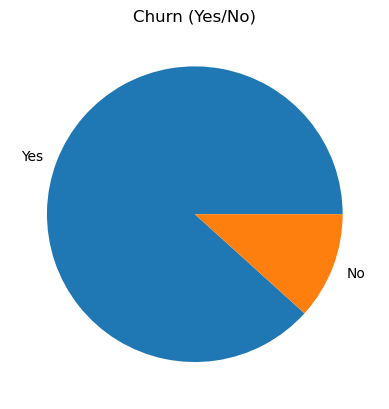

In [26]:
data["Churn"].value_counts().plot(kind="pie")
plt.title("Churn (Yes/No)")
plt.ylabel("")
plt.show()

In [27]:
data.groupby("Churn")["MonthlyCharges"].mean()

Churn
No     62.54641
Yes    75.96077
Name: MonthlyCharges, dtype: float64

In [ ]:
data.groupby("Churn")["MonthlyCharges"].mean()

In [29]:
data.groupby(["Churn","Gender"])["MonthlyCharges"].mean()

Churn  Gender
No     Female    65.091912
       Male      59.013878
Yes    Female    74.975064
       Male      77.082518
Name: MonthlyCharges, dtype: float64

In [30]:
data.groupby("Churn")["Tenure"].mean()

Churn
No     30.264957
Yes    17.476784
Name: Tenure, dtype: float64

In [31]:
data.groupby("Churn")["Age"].mean()

Churn
No     43.487179
Yes    44.831257
Name: Age, dtype: float64

At the lower terms we can see that the monthly charge average decreases

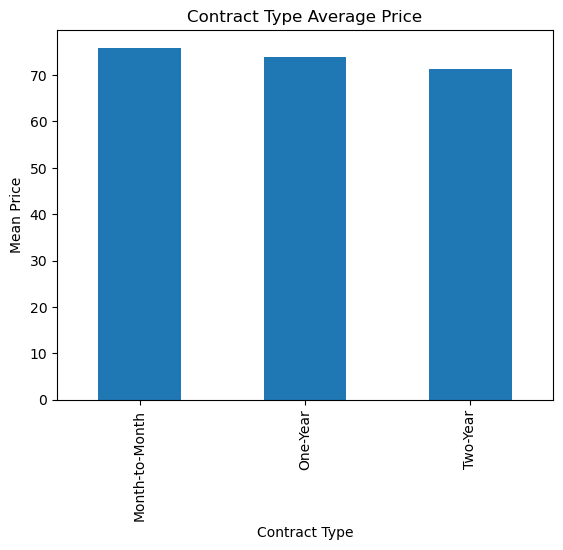

In [33]:
data.groupby("ContractType")["MonthlyCharges"].mean().plot(kind="bar")
plt.ylabel("Mean Price")
plt.xlabel("Contract Type")
plt.title("Contract Type Average Price")
plt.show()

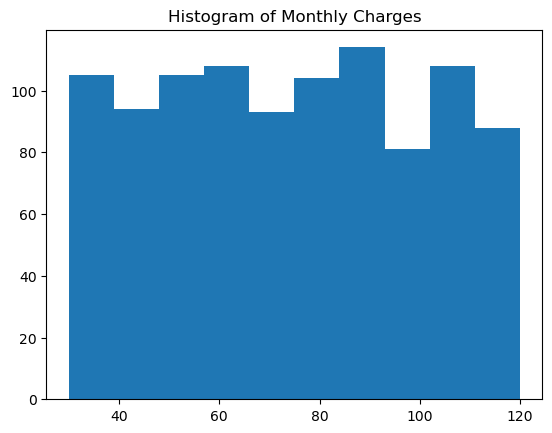

In [34]:
plt.hist(data["MonthlyCharges"])
plt.title("Histogram of Monthly Charges")
plt.show()

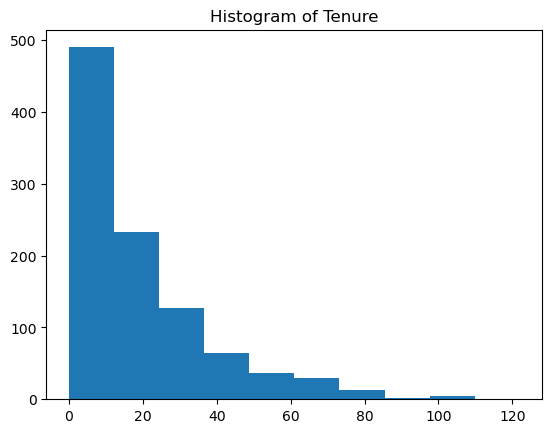

In [35]:
plt.hist(data["Tenure"])
plt.title("Histogram of Tenure")
plt.show()

In [36]:
y=data[["Churn"]]
X=data[["Age","Gender","Tenure","MonthlyCharges"]]

In [42]:
X # 1 Female & 0 male

,Age,Gender,Tenure,MonthlyCharges
0,49,0,4,88.35
1,43,0,0,36.67
2,51,1,2,63.79
3,60,1,8,102.34
4,42,0,32,69.01
...,...,...,...,...
995,42,0,41,37.14
996,62,0,9,80.93
997,51,1,15,111.72
998,39,0,68,65.67


In [41]:
X["Gender"]=X["Gender"].apply(lambda x:1 if x=="Female" else 0)

C:\Users\HP\AppData\Local\Temp\ipykernel_11860\59549676.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X["Gender"]=X["Gender"].apply(lambda x:1 if x=="Female" else 0)


In [38]:
y 

,Churn
0,Yes
1,Yes
2,Yes
3,Yes
4,Yes
...,...
995,Yes
996,Yes
997,Yes
998,Yes


In [44]:
type(X["Gender"][0])

numpy.int64

In [46]:
y["Churn"]=y["Churn"].apply(lambda x:1 if x=="Yes" else 0)

C:\Users\HP\AppData\Local\Temp\ipykernel_11860\248740190.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  y["Churn"]=y["Churn"].apply(lambda x:1 if x=="Yes" else 0)


In [47]:
y.head() #1 yes & 0 No

,Churn
0,1
1,1
2,1
3,1
4,1


In [49]:
type(y["Churn"][0])

numpy.int64

**train_test_split**

In [50]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2)

In [51]:
X

,Age,Gender,Tenure,MonthlyCharges
0,49,0,4,88.35
1,43,0,0,36.67
2,51,1,2,63.79
3,60,1,8,102.34
4,42,0,32,69.01
...,...,...,...,...
995,42,0,41,37.14
996,62,0,9,80.93
997,51,1,15,111.72
998,39,0,68,65.67


In [52]:
from sklearn.preprocessing import StandardScaler

In [53]:
scaler=StandardScaler()

In [54]:
X_train =scaler.fit_transform(X_train)

In [55]:
import joblib
joblib.dump(scaler,"scaler.pkl")

['scaler.pkl']

In [56]:
X_test =scaler.fit_transform(X_test)

In [57]:
X_train

array([[-0.95721643,  0.93933644,  0.95805921, -1.45406649],
       [-1.05825524,  0.93933644, -0.74149839, -0.48286175],
       [ 0.15421048,  0.93933644, -0.63527604, -0.59628712],
       ...,
       [-0.45202238,  0.93933644,  0.95805921, -1.23351716],
       [ 0.45732691,  0.93933644,  0.95805921, -0.52854697],
       [-0.45202238,  0.93933644, -0.42283134, -1.13505764]],
      shape=(800, 4))

In [58]:
X_test

array([[-3.72817650e-01,  8.77446012e-01, -6.81666424e-01,
         3.89958252e-01],
       [-1.76753116e+00, -1.13967126e+00, -9.95798416e-01,
        -2.29276946e-01],
       [-1.66024551e+00,  8.77446012e-01, -5.24600427e-01,
        -1.58080890e+00],
       [-3.72817650e-01,  8.77446012e-01, -9.95798416e-01,
         8.31047107e-01],
       [-9.09245924e-01,  8.77446012e-01, -8.38732420e-01,
         1.92844345e-01],
       [ 1.02189586e+00,  8.77446012e-01, -5.76955760e-01,
        -1.10513213e+00],
       [-3.72817650e-01, -1.13967126e+00, -5.24600427e-01,
        -1.08318927e+00],
       [-1.01653158e+00, -1.13967126e+00, -4.19889763e-01,
         5.93022767e-01],
       [ 1.45103848e+00, -1.13967126e+00, -5.24600427e-01,
         6.60339025e-01],
       [-1.33838854e+00,  8.77446012e-01, -8.38732420e-01,
         5.78890072e-01],
       [ 5.63249687e-02, -1.13967126e+00, -5.24600427e-01,
         1.32643526e+00],
       [-9.09245924e-01, -1.13967126e+00,  4.70150882e-01,
      

In [60]:
from sklearn.metrics import accuracy_score
def modelperformance(predictions):
    print("Accuracy score on model is {}".format(accuracy_score(y_test,predictions)))

In [72]:
from sklearn.model_selection import GridSearchCV

In [63]:
from sklearn.linear_model import LogisticRegression

In [75]:
log_model= LogisticRegression()

In [76]:
import warnings
warnings.filterwarnings("ignore")

In [77]:
log_model.fit(X_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [78]:
X

,Age,Gender,Tenure,MonthlyCharges
0,49,0,4,88.35
1,43,0,0,36.67
2,51,1,2,63.79
3,60,1,8,102.34
4,42,0,32,69.01
...,...,...,...,...
995,42,0,41,37.14
996,62,0,9,80.93
997,51,1,15,111.72
998,39,0,68,65.67


In [81]:
y_pred=log_model.predict(X_test)

In [83]:
modelperformance(y_pred)

Accuracy score on model is 0.89


In [85]:
from sklearn.neighbors import KNeighborsClassifier

In [86]:
param_grid={
    "n_neighbors":[3,5,7,9],
    "weights":["uniform","distance"],
}

In [87]:
gridkn =GridSearchCV(KNeighborsClassifier(),param_grid,cv=5)

In [88]:
gridkn.fit(X_train,y_train)

,estimator,KNeighborsClassifier()
,param_grid,"{'n_neighbors': [3, 5, ...], 'weights': ['uniform', 'distance']}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_neighbors,9


In [89]:
gridkn.best_params_

{'n_neighbors': 9, 'weights': 'uniform'}

In [90]:
y_pred=gridkn.predict(X_test)

In [91]:
modelperformance(y_pred)

Accuracy score on model is 0.885


In [93]:
from sklearn.svm import SVC

In [100]:
svm= SVC()

In [104]:
param_grid={ 
    "C":[0.01,0.1,0.5,1],
    "kernel":["linear","rbf","poly"],
}

In [105]:
gridsvc= GridSearchCV(svm, param_grid, cv=5)

In [106]:
gridsvc.fit(X_train,y_train)

,estimator,SVC()
,param_grid,"{'C': [0.01, 0.1, ...], 'kernel': ['linear', 'rbf', ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,0.01


In [107]:
gridsvc.best_params_

{'C': 0.01, 'kernel': 'linear'}

In [109]:
y_pred=gridsvc.predict(X_test)

In [110]:
modelperformance(y_pred)

Accuracy score on model is 0.895


In [111]:
from sklearn.tree import  DecisionTreeClassifier

In [120]:
param_grid={
    "criterion":["gini","entropy"],
    "splitter":["best","random"],
    "max_depth": [None ,10,20,30],
    "min_samples_split":[2,5,10],
    "min_samples_leaf":[1,2,4]
}

In [121]:
grid_tree=GridSearchCV(DecisionTreeClassifier() , param_grid, cv=5)

In [122]:
grid_tree.fit(X_train,y_train)

,estimator,DecisionTreeClassifier()
,param_grid,"{'criterion': ['gini', 'entropy'], 'max_depth': [None, 10, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'gini'


In [123]:
grid_tree.best_params_

{'criterion': 'gini',
 'max_depth': None,
 'min_samples_leaf': 4,
 'min_samples_split': 10,
 'splitter': 'random'}

In [124]:
y_pred=grid_tree.predict(X_test)

In [125]:
y_pred

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1,
       1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1])

In [126]:
modelperformance(y_pred)

Accuracy score on model is 0.845


In [127]:
from sklearn.ensemble import RandomForestClassifier
rfc_model=RandomForestClassifier()

In [132]:
param_grid= {
    "n_estimators":[32,64,128,256],
    "max_features": [2,3,4],
    "bootstrap":[True,False]
}

In [133]:
grid_rfc=GridSearchCV(rfc_model,param_grid,cv=5)

In [134]:
grid_rfc.fit(X_train,y_train)

,estimator,RandomForestClassifier()
,param_grid,"{'bootstrap': [True, False], 'max_features': [2, 3, ...], 'n_estimators': [32, 64, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,256


In [135]:
grid_rfc.best_params_

{'bootstrap': True, 'max_features': 2, 'n_estimators': 256}

In [136]:
y_pred=grid_rfc.predict(X_test)

In [137]:
modelperformance(y_pred)

Accuracy score on model is 0.885


In [138]:
best_model=gridsvc.best_estimator_

In [139]:
joblib.dump(best_model,"model.pkl")

['model.pkl']

In [140]:
X.columns

Index(['Age', 'Gender', 'Tenure', 'MonthlyCharges'], dtype='object')